# Efficient Medical Image Classification Using Vision Transformers and LoRA Fine-Tuning

This notebook compares frozen-feature, full fine-tuning, and LoRA adaptation on PneumoniaMNIST. It uses MedMNIST's official splits and selects checkpoints on validation macro-F1. Test metrics are computed after model selection.

The backbone is a compact ImageNet-21k-pretrained and ImageNet-1k-fine-tuned ViT-Tiny (Apache-2.0, 224 × 224 input). PneumoniaMNIST provides 28 × 28 grayscale chest X-rays. Resizing them to 224 × 224 lets them fit the ViT input, but does not restore visual detail. This is an educational benchmark, not clinical software.

In [1]:
# Colab includes PyTorch in its standard runtime; we report that version before installing the remaining dependencies.
# This makes environment issues visible early without replacing the runtime's CUDA-enabled PyTorch.
# Colab runtime and the small set of libraries used below.
import sys, subprocess, platform, os, random, time, copy, json
from pathlib import Path
import numpy as np
import torch

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable; training will use CPU and may take substantially longer.")

# Colab already provides PyTorch; install only the project-specific packages used below.
# Keep this list in sync with the imports used later in the notebook.
# Pinning the notebook dependencies makes reruns less sensitive to package releases.
packages = ["medmnist==3.0.2", "timm==1.0.15", "scikit-learn==1.6.1",
            "seaborn==0.13.2", "tqdm==4.67.1", "matplotlib==3.10.1", "pandas==2.2.3"]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])

Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA: 13.0
GPU: Tesla T4


0

In [2]:
# The imports below cover data handling, model construction, training, metrics, and plots.
# PEFT is not needed here: the small LoRA wrapper is implemented directly around timm's Linear layer.
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import timm
import medmnist
from medmnist import INFO
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

SEED = 42
# These are the experiment controls: reduce batch size first if the selected Colab GPU runs out of memory.
# The frozen and LoRA runs can use a larger learning rate than full encoder fine-tuning.
BATCH_SIZE = 64
LEARNING_RATE = 3e-4
IMAGE_SIZE = 224
EPOCHS = 5
LORA_RANK = 8
LORA_ALPHA = 16
PATIENCE = 2
NUM_WORKERS = 2
DATASET_SIZE = 28
REUSE_CHECKPOINTS = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = torch.cuda.is_available()
# These settings are grouped here because they are the values most likely to change between runs.
# A fixed seed helps comparisons, although some GPU operations can still be nondeterministic.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"
AMP_DTYPE = torch.float16
PROJECT_DIR = Path("/content/pneumoniamnist-lora")
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
# Keep all generated artifacts together so the notebook can be rerun or copied from Colab in one step.
for directory in (RESULTS_DIR, FIGURES_DIR, CHECKPOINT_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print(f"Device: {DEVICE}; mixed precision: {AMP_ENABLED}")

Device: cuda; mixed precision: True


## Load and inspect PneumoniaMNIST

PneumoniaMNIST is a small binary classification dataset of pediatric chest X-rays. The standard MedMNIST files are 28 × 28 and have official train, validation, and test splits. The loader checks split sizes and labels from the downloaded files.

In [3]:
# PneumoniaMNIST is much smaller than the 224-pixel MedMNIST+ downloads.
# The standard dataset has 5,856 small grayscale images and downloads quickly.
DATA_FLAG = "pneumoniamnist"
dataset_info = INFO[DATA_FLAG]
DatasetClass = getattr(medmnist, dataset_info["python_class"])
DATASET_SIZE = 28

# MedMNIST expects the root folder to exist, including in a fresh Colab runtime.
DATA_ROOT = PROJECT_DIR / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)


def load_splits():
    # Request only the standard 28 x 28 dataset files.
    common = {"download": True, "root": str(DATA_ROOT), "size": DATASET_SIZE}
    try:
        return {
            split: DatasetClass(split=split, **common)
            for split in ("train", "val", "test")
        }
    except Exception as error:
        raise RuntimeError(
            f"Could not download or initialize PneumoniaMNIST in {DATA_ROOT}. "
            "Check that the directory is writable and Colab has network access."
        ) from error


raw_splits = load_splits()
class_names = list(dataset_info["label"].values())
num_classes = len(class_names)

# Read split sizes and labels from the loaded files rather than assuming them.
split_sizes = {name: len(data) for name, data in raw_splits.items()}
labels_by_split = {
    name: np.asarray(data.labels).reshape(-1).astype(int)
    for name, data in raw_splits.items()
}

assert num_classes == 2, f"Expected two classes, found {num_classes}"
for split_name, labels in labels_by_split.items():
    assert len(labels) == split_sizes[split_name]
    assert set(labels).issubset(range(num_classes)), (
        f"Unexpected label values in the {split_name} split"
    )

print("Dataset:", dataset_info["description"])
print("Standard image size: 28 x 28 grayscale")
print("Split sizes:", split_sizes)
print("Class labels:", dict(enumerate(class_names)))
print(
    "Label range by split:",
    {
        name: (int(labels.min()), int(labels.max()))
        for name, labels in labels_by_split.items()
    },
)

sample_image, sample_label = raw_splits["train"][0]
print("Sample image:", sample_image.size, sample_image.mode, type(sample_image).__name__)
print("Raw label:", np.asarray(sample_label).shape, sample_label)


100%|██████████| 4.17M/4.17M [00:47<00:00, 86.9kB/s]

Dataset: The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.
Standard image size: 28 x 28 grayscale
Split sizes: {'train': 4708, 'val': 524, 'test': 624}
Class labels: {0: 'normal', 1: 'pneumonia'}
Label range by split: {'train': (0, 1), 'val': (0, 1), 'test': (0, 1)}
Sample image: (28, 28) L Image
Raw label: (1,) [1]


,class_id,class_name,train,validation,test
0,0,normal,1214,135,234
1,1,pneumonia,3494,389,390


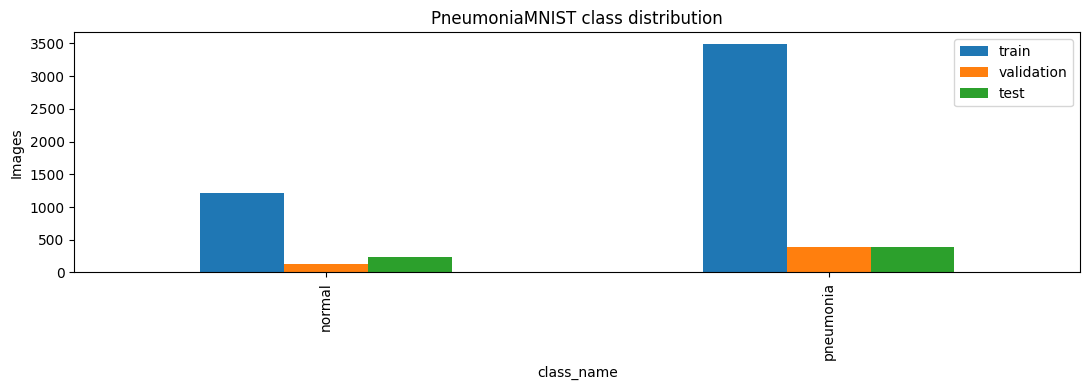

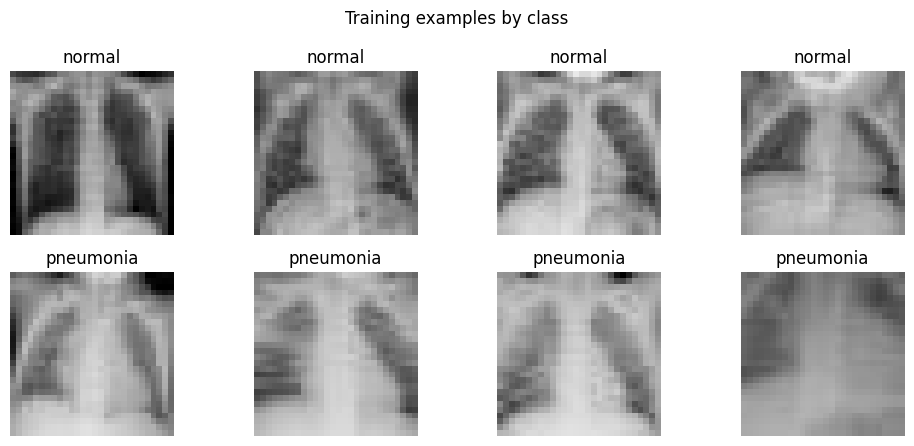

In [4]:
# Counts are computed from observed labels so a changed dataset version is not silently misrepresented.
# Keep this table visible in the notebook as a quick check for split imbalance.
distribution = pd.DataFrame({
    "class_id": np.arange(num_classes),
    "class_name": class_names,
    "train": np.bincount(labels_by_split["train"], minlength=num_classes),
    "validation": np.bincount(labels_by_split["val"], minlength=num_classes),
    "test": np.bincount(labels_by_split["test"], minlength=num_classes),
})
display(distribution)
distribution.set_index("class_name")[["train", "validation", "test"]].plot(
    kind="bar", figsize=(11, 4), ylabel="Images", title="PneumoniaMNIST class distribution")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=160)
plt.show()

# The bars use labels from the official splits, making class imbalance visible before training.
# The image grid is a quick sanity check rather than a curated selection.
# Show examples from each label instead of sampling only from the beginning of the split.
# PneumoniaMNIST images are grayscale; a gray colormap avoids misleading false color.
samples_per_class = 4
fig, axes = plt.subplots(
    num_classes, samples_per_class,
    figsize=(10, 4.5),
    squeeze=False,
)
for class_id in range(num_classes):
    class_indices = np.flatnonzero(labels_by_split["train"] == class_id)
    chosen_indices = class_indices[:samples_per_class]
    for column, index in enumerate(chosen_indices):
        image, _ = raw_splits["train"][index]
        axes[class_id, column].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[class_id, column].set_title(class_names[class_id])
        axes[class_id, column].axis("off")
    for column in range(len(chosen_indices), samples_per_class):
        axes[class_id, column].set_visible(False)

plt.suptitle("Training examples by class")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "sample_images.png", dpi=160)
plt.show()

## Preprocessing and loaders

The preprocessing uses the mean and standard deviation reported by timm for this checkpoint (0.5 per RGB channel). The small images are resized for ViT's 224 × 224 input. Training uses only a light random horizontal flip; validation and test transforms are deterministic.

In [5]:
# timm reports this checkpoint's input mean and standard deviation as 0.5 per channel.
# Match its resolved config rather than using the usual ImageNet normalization values.
# Resizing changes the tensor shape, not the information content of a 28-pixel image.
data_config = {
    "input_size": (3, IMAGE_SIZE, IMAGE_SIZE),
    "mean": (0.5, 0.5, 0.5),
    "std": (0.5, 0.5, 0.5),
}
# Keep augmentation light and training-only; validation and test inputs stay deterministic.
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(data_config["mean"], data_config["std"]),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(data_config["mean"], data_config["std"]),
])

# A small wrapper keeps the MedMNIST download object separate from PyTorch's transform pipeline.
# Labels become plain Python integers, which collate cleanly into a batch of class indices.
class PneumoniaMNISTDataset(Dataset):
    def __init__(self, medmnist_dataset, transform):
        self.dataset = medmnist_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        image = image.convert("RGB")
        label = int(np.asarray(label).item())
        return self.transform(image), label

# Use the checkpoint's resolved normalization; keep random augmentation training-only.
# Random augmentation is limited to training so validation stays repeatable.
datasets = {
    "train": PneumoniaMNISTDataset(raw_splits["train"], train_transform),
    "val": PneumoniaMNISTDataset(raw_splits["val"], eval_transform),
    "test": PneumoniaMNISTDataset(raw_splits["test"], eval_transform),
}
# Only the training loader shuffles; validation and test order is stable for repeatable inspection.
# Pinned memory can speed host-to-GPU transfer, while persistent workers avoid respawning each epoch.
loaders = {
    split: DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=(split == "train"),
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0),
    )
    for split, dataset in datasets.items()
}
images, labels = next(iter(loaders["train"]))
print("Batch:", tuple(images.shape), images.dtype, tuple(labels.shape), labels.dtype)
assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.min() >= 0 and labels.max() < num_classes

Batch: (64, 3, 224, 224) torch.float32 (64,) torch.int64


## Model choice and LoRA

The checkpoint is `timm/vit_tiny_patch16_224.augreg_in21k_ft_in1k`: a 5.7M-parameter ViT-Tiny trained on ImageNet-21k and fine-tuned on ImageNet-1k, not a chest-radiograph-specific model. Its 224-pixel input uses the checkpoint normalization above. Inspecting the instantiated architecture shows each transformer block's fused `attn.qkv` linear projection. The implementation below applies LoRA to that projection.

For a pretrained weight matrix, LoRA uses `W' = W + (alpha / r) BA`. It freezes `W` and learns low-rank matrices `A` and `B`; the new classifier head is trained alongside them.

In [6]:
# The model card describes an ImageNet-21k pretrained, ImageNet-1k fine-tuned ViT-Tiny.
# We use the timm model directly so the attention module names can be inspected before adapting them.
MODEL_ID = "hf-hub:timm/vit_tiny_patch16_224.augreg_in21k_ft_in1k"

# Keep this factory identical across runs so each configuration starts from the same pretrained weights.
# Resetting the classifier to two outputs creates a new PneumoniaMNIST head on every configuration.
# The explicit input size matches the preprocessing above and the model's patch-16 design.
def new_base_model():
    model = timm.create_model(MODEL_ID, pretrained=True, num_classes=num_classes, img_size=IMAGE_SIZE)
    return model

inspection_model = new_base_model()
print(inspection_model.blocks[0].attn)
print("Classifier:", inspection_model.get_classifier())
print("Model data config:", timm.data.resolve_model_data_config(inspection_model))
del inspection_model

# Wrap the original projection instead of replacing its pretrained weight with a new random matrix.
# The wrapped linear layer still computes the original projection; its pretrained weights are frozen.
# The learned residual is low rank, so it adds far fewer trainable weights than updating the full projection.
class LoRALinear(nn.Module):
    def __init__(self, base_layer, rank, alpha, dropout=0.05):
        super().__init__()
        if not isinstance(base_layer, nn.Linear):
            raise TypeError(f"LoRA target must be nn.Linear; got {type(base_layer).__name__}")
        self.base = base_layer
        self.rank = rank
        self.scaling = alpha / rank
        self.dropout = nn.Dropout(dropout)
        self.lora_A = nn.Parameter(torch.empty(rank, base_layer.in_features))
        # Zero-initializing B makes the initial low-rank update exactly zero.
        self.lora_B = nn.Parameter(torch.zeros(base_layer.out_features, rank))
        nn.init.kaiming_uniform_(self.lora_A, a=np.sqrt(5))
        for parameter in self.base.parameters():
            parameter.requires_grad = False

# Compute the original projection and the low-rank residual separately for clarity.
# Applying A and then B is equivalent to the BA update without materializing the full product.
    def forward(self, inputs):
        base_output = self.base(inputs)
        update = nn.functional.linear(
            nn.functional.linear(self.dropout(inputs), self.lora_A), self.lora_B)
        return base_output + self.scaling * update

# timm's ViT-Tiny uses one fused q/k/v projection per attention block.
# Apply LoRA to each transformer's fused query/key/value projection, not the MLP or classifier.
# The guard makes an architecture change fail loudly instead of producing a misleading LoRA run.
def replace_attention_qkv(model, rank=LORA_RANK, alpha=LORA_ALPHA):
    replaced = 0
    for block in model.blocks:
        block.attn.qkv = LoRALinear(block.attn.qkv, rank=rank, alpha=alpha)
        replaced += 1
    if replaced == 0:
        raise RuntimeError("No attention qkv projections were found; inspect the timm model structure.")
    return replaced

# Freeze before inserting LoRA so only adapter matrices and the task head are trainable.
# All configurations start from the original public checkpoint, never from another experiment's weights.
# Frozen trains the head; full fine-tuning trains everything; LoRA trains only adapters and the head.
def configure_model(config_name):
    model = new_base_model()
    if config_name == "frozen":
        for parameter in model.parameters():
            parameter.requires_grad = False
        for parameter in model.get_classifier().parameters():
            parameter.requires_grad = True
    elif config_name == "full":
        for parameter in model.parameters():
            parameter.requires_grad = True
    elif config_name == "lora":
        for parameter in model.parameters():
            parameter.requires_grad = False
        replace_attention_qkv(model)
        for parameter in model.get_classifier().parameters():
            parameter.requires_grad = True
    else:
        raise ValueError(f"Unknown model configuration: {config_name}")
    return model

# Inspecting this checkpoint confirms that each block uses a fused qkv attention projection.
# The forward and backward smoke test catches shape or gradient issues before training.
smoke_model = configure_model("lora").to(DEVICE)
trainable = [p for p in smoke_model.parameters() if p.requires_grad]
frozen_backbone = [p for n, p in smoke_model.named_parameters()
                   if "lora_" not in n and "head" not in n]
# The smoke test checks both the intended freeze pattern and gradient flow into LoRA.
# A successful forward pass alone would not catch an adapter that accidentally receives no gradients.
assert trainable and all(not p.requires_grad for p in frozen_backbone)
smoke_logits = smoke_model(images[:2].to(DEVICE))
smoke_loss = nn.CrossEntropyLoss()(smoke_logits, labels[:2].to(DEVICE))
smoke_loss.backward()
assert any(p.grad is not None and p.grad.abs().sum() > 0
           for n, p in smoke_model.named_parameters() if "lora_" in n)
print("Smoke test passed:", tuple(smoke_logits.shape), "loss", smoke_loss.detach().item())
del smoke_model, trainable, frozen_backbone, smoke_logits, smoke_loss
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Attention(
  (qkv): Linear(in_features=192, out_features=576, bias=True)
  (q_norm): Identity()
  (k_norm): Identity()
  (attn_drop): Dropout(p=0.0, inplace=False)
  (proj): Linear(in_features=192, out_features=192, bias=True)
  (proj_drop): Dropout(p=0.0, inplace=False)
)
Classifier: Linear(in_features=192, out_features=2, bias=True)
Model data config: {'input_size': [3, 224, 224], 'interpolation': 'bicubic', 'mean': [0.5, 0.5, 0.5], 'std': [0.5, 0.5, 0.5], 'crop_pct': 0.9, 'crop_mode': 'center'}
Smoke test passed: (2, 2) loss 0.750289797782898


## Training and checkpoint selection

All three configurations start from the same public pretrained checkpoint. The frozen-feature run trains only its new classifier head; full fine-tuning updates the encoder and head; LoRA trains the inserted low-rank matrices and head. A short, configurable epoch budget and validation macro-F1 early stopping keep Colab runs manageable. The test split is held for final evaluation.

In [7]:
# CUDA autocast reduces activation memory; CPU runs keep ordinary float32 behavior.
# Autocast is used only on CUDA, where half precision can reduce activation memory.
# CPU execution stays in its normal precision to avoid unsupported or slower half-precision operations.
def autocast_context():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE) if AMP_ENABLED else torch.autocast("cpu", enabled=False)

# The batch loop is kept visible so the gradient and optimizer steps are easy to follow.
# Validation runs through the same code path without updating weights.
# Passing an optimizer marks this as a training pass; without one, autograd and weight updates are disabled.
# Loss is accumulated by sample count so the final partial batch is weighted correctly.
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, all_targets, all_predictions = 0.0, [], []
    progress = tqdm(loader, leave=False)
# Move one batch at a time to the selected device instead of copying the full dataset into GPU memory.
# non_blocking works with pinned batches and is harmless when running on CPU.
    for batch_images, batch_labels in progress:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        batch_labels = batch_labels.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with autocast_context():
                logits = model(batch_images)
                loss = criterion(logits, batch_labels)
            if training:
                if scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()
        total_loss += loss.item() * len(batch_labels)
        all_targets.extend(batch_labels.detach().cpu().tolist())
        all_predictions.extend(logits.argmax(1).detach().cpu().tolist())
        progress.set_postfix(loss=f"{loss.item():.3f}")
    return total_loss / len(loader.dataset), np.asarray(all_targets), np.asarray(all_predictions)

def parameter_counts(model):
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    return total, trainable, 100 * trainable / total

# AdamW is a simple common optimizer here; full fine-tuning gets a smaller learning rate.
# The history is kept in memory for plots, and the checkpoint stores the best validation-selected weights.
def fit_configuration(config_name):
    model = configure_model(config_name).to(DEVICE)
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LEARNING_RATE if config_name != "full" else 5e-5,
        weight_decay=0.01,
    )
    # Gradient scaling prevents fp16 underflow and is disabled automatically on CPU.
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}
    best_score, best_state, stale_epochs = -1.0, None, 0
    checkpoint_path = CHECKPOINT_DIR / f"{config_name}_best.pt"
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()

# Reuse is opt-in because stale checkpoints can otherwise be mistaken for a fresh experiment.
# In Colab, copy these files to Drive if they need to survive a runtime reset.
    if REUSE_CHECKPOINTS and checkpoint_path.exists():
        # Restore the best validation checkpoint, not necessarily the final epoch.
        saved = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(saved["model_state"])
        history = saved["history"]
        best_score = max(history["val_macro_f1"])
        print(f"Loaded existing {config_name} checkpoint; history is reused.")
    else:
# One epoch contains a training pass followed by a no-gradient validation pass.
# Early stopping uses validation macro-F1, leaving the test split untouched until final evaluation.
        for epoch in range(EPOCHS):
            train_loss, _, _ = run_epoch(model, loaders["train"], criterion, optimizer, scaler)
            val_loss, val_targets, val_predictions = run_epoch(model, loaders["val"], criterion)
            val_f1 = precision_recall_fscore_support(
                val_targets, val_predictions, average="macro", zero_division=0)[2]
            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["val_macro_f1"].append(float(val_f1))
            print(f"{config_name} | epoch {epoch + 1}/{EPOCHS} | "
                  f"train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
                  f"val macro-F1 {val_f1:.4f}")
            # Validation macro-F1 selects the saved weights; test data is never consulted here.
            if val_f1 > best_score:
                best_score, stale_epochs = float(val_f1), 0
                best_state = copy.deepcopy(model.state_dict())
                torch.save({"model_state": best_state, "history": history}, checkpoint_path)
            else:
                stale_epochs += 1
                if stale_epochs >= PATIENCE:
                    print("Early stopping: validation macro-F1 did not improve.")
                    break
        saved = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(saved["model_state"])

    elapsed = time.perf_counter() - started
    peak_memory_mb = (torch.cuda.max_memory_allocated() / 1024**2
                      if DEVICE.type == "cuda" else np.nan)
    total, trainable, trainable_pct = parameter_counts(model)
    return model, history, {
        "configuration": config_name, "total_parameters": total,
        "trainable_parameters": trainable, "trainable_percent": trainable_pct,
        "training_seconds": elapsed, "peak_gpu_memory_mb": peak_memory_mb,
        "checkpoint_path": str(checkpoint_path),
    }

models, histories, efficiency = {}, {}, {}
for name in ("frozen", "full", "lora"):
    models[name], histories[name], efficiency[name] = fit_configuration(name)

  0%|          | 0/74 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

frozen | epoch 1/5 | train loss 0.3546 | val loss 0.2720 | val macro-F1 0.8588


  0%|          | 0/74 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

...

  0%|          | 0/9 [00:00<?, ?it/s]

lora | epoch 4/5 | train loss 0.0687 | val loss 0.0812 | val macro-F1 0.9672


  0%|          | 0/74 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

lora | epoch 5/5 | train loss 0.0596 | val loss 0.0751 | val macro-F1 0.9701


## Final test evaluation

The same evaluation routine is used for each selected checkpoint. ROC-AUC is computed with one-vs-rest targets and is recorded as unavailable if a class is absent from the test labels or the calculation fails.

In [8]:
# Inference mode avoids building autograd graphs and reduces evaluation memory use.
# We return probabilities, rather than only labels, because AUC needs confidence scores.
@torch.inference_mode()
def predict_probabilities(model, loader):
    model.eval()
    all_targets, all_probabilities = [], []
    for batch_images, batch_labels in tqdm(loader, leave=False):
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        with autocast_context():
            logits = model(batch_images)
        all_targets.extend(batch_labels.numpy().tolist())
        all_probabilities.extend(logits.float().softmax(dim=1).cpu().numpy())
    return np.asarray(all_targets), np.asarray(all_probabilities)

# Every model uses the same test loader and metric code.
# Retaining probabilities lets AUC and ROC plots use model predictions directly.
comparison_rows, per_class_rows, test_outputs = [], [], {}
# Each row is calculated from actual test predictions produced by the selected checkpoint.
# zero_division=0 keeps per-class metrics defined when a model never predicts a class.
for name, model in models.items():
    targets, probabilities = predict_probabilities(model, loaders["test"])
    predictions = probabilities.argmax(axis=1)
    test_outputs[name] = (targets, predictions, probabilities)
    precision, recall, f1, support = precision_recall_fscore_support(
        targets, predictions, labels=np.arange(num_classes), zero_division=0)
    # AUC is undefined if the test split lacks a class, so retain NaN in that case.
    try:
        # Binary AUC uses the positive-class score; multiclass AUC uses one-vs-rest.
        if num_classes == 2:
            macro_auc = roc_auc_score(targets, probabilities[:, 1])
        else:
            macro_auc = roc_auc_score(
                targets, probabilities, labels=np.arange(num_classes),
                multi_class="ovr", average="macro")
    except ValueError:
        macro_auc = np.nan
    comparison_rows.append({
        "configuration": name,
        "accuracy": accuracy_score(targets, predictions),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "macro_f1": f1.mean(),
        "weighted_f1": precision_recall_fscore_support(
            targets, predictions, average="weighted", zero_division=0)[2],
        "macro_ovr_roc_auc": macro_auc,
    })
    for class_id, class_name in enumerate(class_names):
        per_class_rows.append({
            "configuration": name, "class_id": class_id, "class_name": class_name,
            "precision": precision[class_id], "recall": recall[class_id],
            "f1": f1[class_id], "support": support[class_id],
        })
    print(f"\n{name} classification report")
    print(classification_report(targets, predictions, target_names=class_names, zero_division=0))

comparison = pd.DataFrame(comparison_rows).merge(pd.DataFrame(efficiency.values()), on="configuration")
per_class_metrics = pd.DataFrame(per_class_rows)
display(comparison.round(4))
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
per_class_metrics.to_csv(RESULTS_DIR / "per_class_metrics.csv", index=False)
comparison[["configuration", "total_parameters", "trainable_parameters",
            "trainable_percent", "training_seconds", "peak_gpu_memory_mb",
            "checkpoint_path"]].to_csv(RESULTS_DIR / "efficiency_comparison.csv", index=False)

  0%|          | 0/10 [00:00<?, ?it/s]


frozen classification report
              precision    recall  f1-score   support

      normal       0.93      0.59      0.72       234
   pneumonia       0.80      0.97      0.88       390

    accuracy                           0.83       624
   macro avg       0.86      0.78      0.80       624
weighted avg       0.85      0.83      0.82       624



  0%|          | 0/10 [00:00<?, ?it/s]


full classification report
              precision    recall  f1-score   support

      normal       0.99      0.65      0.78       234
   pneumonia       0.82      0.99      0.90       390

    accuracy                           0.86       624
   macro avg       0.91      0.82      0.84       624
weighted avg       0.88      0.86      0.86       624



  0%|          | 0/10 [00:00<?, ?it/s]


lora classification report
              precision    recall  f1-score   support

      normal       0.98      0.68      0.80       234
   pneumonia       0.84      0.99      0.91       390

    accuracy                           0.88       624
   macro avg       0.91      0.84      0.86       624
weighted avg       0.89      0.88      0.87       624



,configuration,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,macro_ovr_roc_auc,total_parameters,trainable_parameters,trainable_percent,training_seconds,peak_gpu_memory_mb,checkpoint_path
0,frozen,0.8285,0.8643,0.7799,0.7979,0.8176,0.9237,5524802,386,0.0070,64.7673,170.0786,/content/pneumoniamnist-lora/checkpoints/froze...
1,full,0.8638,0.9054,0.8201,0.8408,0.8559,0.9779,5524802,5524802,100.0000,44.1694,1239.5220,/content/pneumoniamnist-lora/checkpoints/full_...
2,lora,0.8750,0.9096,0.8359,0.8557,0.8689,0.9718,5598530,74114,1.3238,67.2933,960.5483,/content/pneumoniamnist-lora/checkpoints/lora_...


Macro-F1 gives each class equal weight, so strong performance on common classes cannot hide weak performance on a smaller class. Weighted F1 reflects the observed class frequencies. The official test split is used only for these final reports, not for choosing epochs or checkpoints.

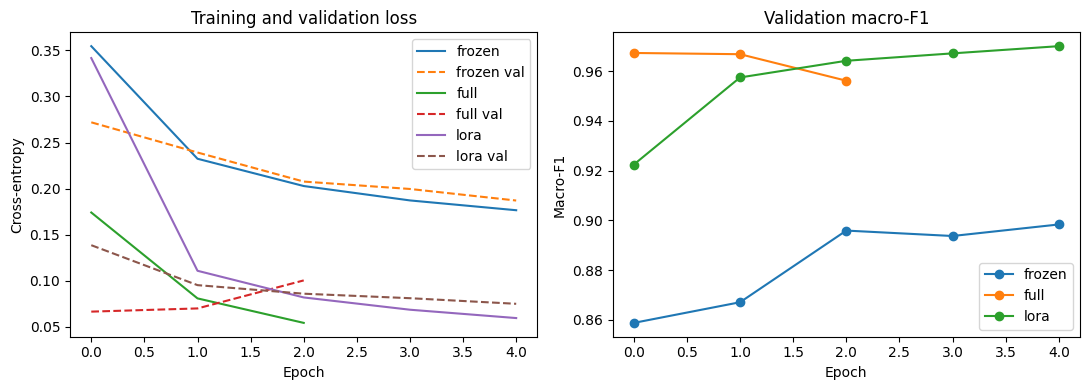

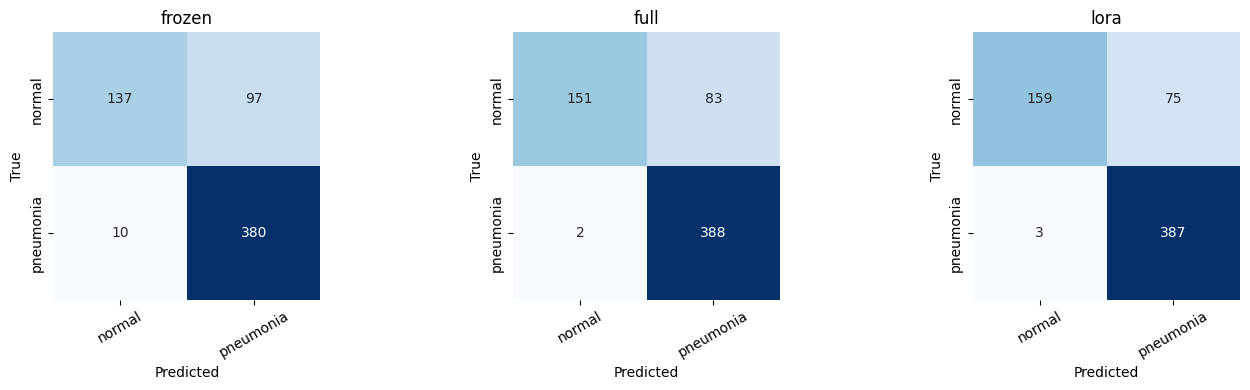

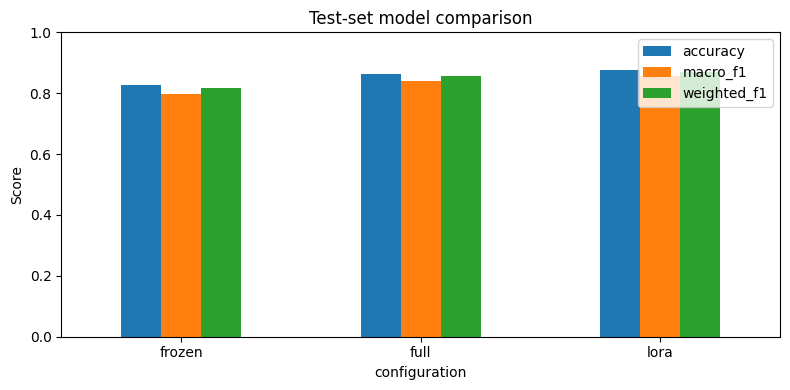

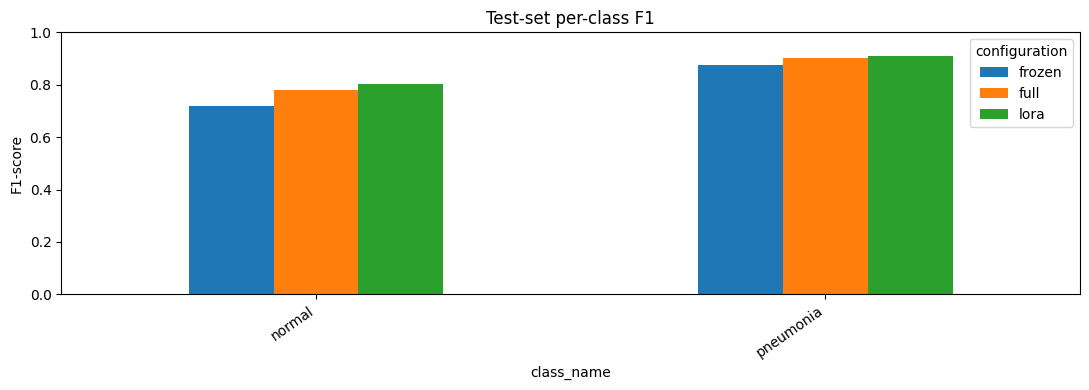

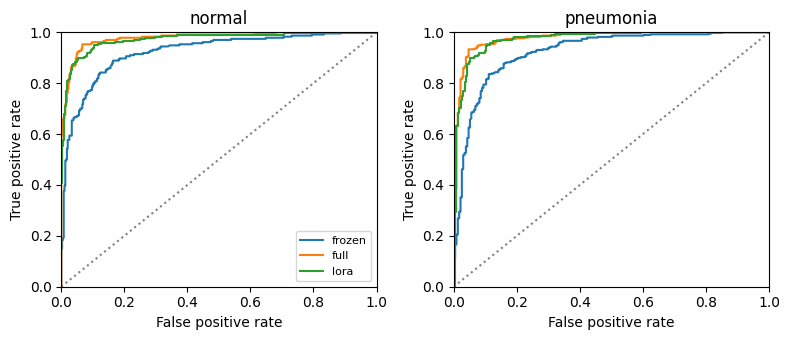

In [9]:
# Training histories use the best-run training trajectory; selected checkpoints are chosen on validation macro-F1.
# The curves keep validation behavior visible alongside training loss.
# Confusion matrices show which labels are being mixed up.
# Training and validation losses use separate line styles so they remain distinguishable.
# The macro-F1 panel shows the validation signal used for checkpoint selection.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, history in histories.items():
    axes[0].plot(history["train_loss"], label=name)
    axes[0].plot(history["val_loss"], linestyle="--", label=f"{name} val")
    axes[1].plot(history["val_macro_f1"], marker="o", label=name)
axes[0].set(title="Training and validation loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_curves.png", dpi=160)
plt.show()

# Confusion matrices share the same class ordering and color scale for visual comparison.
# The model comparison chart focuses on complementary test metrics rather than one score alone.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, (targets, predictions, _)) in zip(axes, test_outputs.items()):
    sns.heatmap(
        confusion_matrix(targets, predictions, labels=np.arange(num_classes)),
        cmap="Blues",
        annot=True,
        fmt="d",
        square=True,
        ax=ax,
        cbar=False,
        xticklabels=class_names,
        yticklabels=class_names,
    )
    ax.set(title=name, xlabel="Predicted", ylabel="True")
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrices.png", dpi=160)
plt.show()

comparison.set_index("configuration")[["accuracy", "macro_f1", "weighted_f1"]].plot(
    kind="bar", ylim=(0, 1), figsize=(8, 4), ylabel="Score", title="Test-set model comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison.png", dpi=160)
plt.show()

pivot_f1 = per_class_metrics.pivot(index="class_name", columns="configuration", values="f1")
pivot_f1.plot(kind="bar", figsize=(11, 4), ylabel="F1-score", ylim=(0, 1),
              title="Test-set per-class F1")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "per_class_f1.png", dpi=160)
plt.show()

# Use a spread of indices through the training split instead of showing nine adjacent records.
# Titles come from the dataset's label map so the sample grid also checks label decoding.
# Build one ROC panel per class so this plot also works when the dataset has only two labels.
ncols = min(3, num_classes)
nrows = int(np.ceil(num_classes / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)
for class_id, ax in enumerate(axes.flat[:num_classes]):
    for name, (targets, _, probabilities) in test_outputs.items():
        binary_targets = (targets == class_id).astype(int)
        if binary_targets.min() == binary_targets.max():
            continue
        false_positive_rate, true_positive_rate, _ = roc_curve(
            binary_targets, probabilities[:, class_id])
        ax.plot(false_positive_rate, true_positive_rate, label=name)
    ax.plot([0, 1], [0, 1], color="gray", linestyle=":")
    ax.set(title=class_names[class_id], xlabel="False positive rate",
           ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
axes[0, 0].legend(fontsize=8)
for ax in axes.flat[num_classes:]:
    ax.set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_curves.png", dpi=160)
plt.show()


## Efficiency, adapter export, and inference timing

The full checkpoint contains all model parameters. The LoRA adapter artifact contains only the attention low-rank matrices and classifier state; loading it still requires the original pretrained backbone. Inference is benchmarked on the same test loader after warm-up. GPU timings synchronize the device so the reported time includes completed kernels.

In [10]:
def checkpoint_size_mb(path):
    return Path(path).stat().st_size / 1024**2

# Save only the low-rank matrices and task head; inference still needs the original pretrained backbone.
# The adapter export omits frozen backbone tensors to keep task-specific storage small.
# The metadata records the base model and LoRA settings needed to rebuild the same module layout.
def save_lora_adapter(model, directory):
    directory.mkdir(parents=True, exist_ok=True)
    adapter_state = {
        name: tensor.detach().cpu()
        for name, tensor in model.state_dict().items()
        if "lora_A" in name or "lora_B" in name or name.startswith("head.")
    }
    path = directory / "adapter_and_head.pt"
    torch.save({
        "model_id": MODEL_ID, "image_size": IMAGE_SIZE,
        "num_classes": num_classes, "rank": LORA_RANK, "alpha": LORA_ALPHA,
        "class_names": class_names, "state_dict": adapter_state,
    }, path)
    return path

# Full checkpoints and adapter files answer different storage questions.
# All models use the same warm-up and test batches for latency measurement.
adapter_path = save_lora_adapter(models["lora"], CHECKPOINT_DIR / "lora_adapter")
for name, details in efficiency.items():
    details["checkpoint_size_mb"] = checkpoint_size_mb(details["checkpoint_path"])
efficiency["lora"]["adapter_and_head_size_mb"] = checkpoint_size_mb(adapter_path)
efficiency_frame = pd.DataFrame(efficiency.values())
efficiency_frame.to_csv(RESULTS_DIR / "efficiency_comparison.csv", index=False)
display(efficiency_frame[[
    "configuration", "total_parameters", "trainable_parameters", "trainable_percent",
    "training_seconds", "peak_gpu_memory_mb", "checkpoint_size_mb",
    "adapter_and_head_size_mb"
]].round(3))

# Inference mode avoids building autograd graphs and reduces evaluation memory use.
# We return probabilities, rather than only labels, because AUC needs confidence scores.
@torch.inference_mode()
# Warm-up batches are excluded; CUDA synchronization makes timings include completed GPU work.
# Warm-up lets one-time CUDA setup happen before recording timings.
# We time each batch and report per-image latency, synchronizing CUDA around the timed section.
def measure_inference_ms(model, loader, warmup_batches=5):
    model.eval()
    batch_times = []
    for batch_index, (batch_images, _) in enumerate(loader):
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        started = time.perf_counter()
        with autocast_context():
            model(batch_images)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - started
        if batch_index >= warmup_batches:
            batch_times.append(elapsed / len(batch_images) * 1000)
    if not batch_times:
        raise RuntimeError("Not enough batches to measure inference after warm-up.")
    return float(np.mean(batch_times))

# Each row is calculated from actual test predictions produced by the selected checkpoint.
# zero_division=0 keeps per-class metrics defined when a model never predicts a class.
# Latency depends on the runtime and batch shape, so these measurements describe this run only.
# Adapter size is listed separately from the full checkpoint because the base model is still required.
for name, model in models.items():
    efficiency[name]["inference_ms_per_image"] = measure_inference_ms(model, loaders["test"])
efficiency_frame = pd.DataFrame(efficiency.values())
efficiency_frame.to_csv(RESULTS_DIR / "efficiency_comparison.csv", index=False)
print("Wrote results and figures to", PROJECT_DIR)
print("Inference milliseconds per image:", {
    name: round(details["inference_ms_per_image"], 3)
    for name, details in efficiency.items()
})
comparison = comparison.drop(columns=[
    column for column in efficiency_frame.columns
    if column != "configuration" and column in comparison.columns
], errors="ignore").merge(efficiency_frame, on="configuration")
comparison.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)


,configuration,total_parameters,trainable_parameters,trainable_percent,training_seconds,peak_gpu_memory_mb,checkpoint_size_mb,adapter_and_head_size_mb
0,frozen,5524802,386,0.007,64.767,170.079,21.132,NaN
1,full,5524802,5524802,100.000,44.169,1239.522,21.131,NaN
2,lora,5598530,74114,1.324,67.293,960.548,21.421,0.291


Wrote results and figures to /content/pneumoniamnist-lora
Inference milliseconds per image: {'frozen': 0.572, 'full': 0.622, 'lora': 0.594}


### Reload check

A LoRA model can be reconstructed from the original pretrained checkpoint, the same LoRA structure, and its saved adapter/head state. The check below compares predictions on a fixed batch. Keep the adapter separate from the original pretrained model files when sharing storage.

In [11]:
# Recreate the model from the base checkpoint, then restore just the adapter and classifier tensors.
# This reconstructs the task model from the public base plus the exported adapter and head.
# Matching logits confirms the adapter artifact preserves the trained prediction behavior.
# Recreate the LoRA module from the original checkpoint before loading its task-specific tensors.
# The maximum logit difference checks serialization, not generalization or clinical reliability.
reload_payload = torch.load(adapter_path, map_location="cpu", weights_only=False)
reloaded_lora = configure_model("lora")
reloaded_lora.load_state_dict(reload_payload["state_dict"], strict=False)
reloaded_lora = reloaded_lora.to(DEVICE).eval()
reference_images, _ = next(iter(loaders["test"]))
with torch.inference_mode(), autocast_context():
    reference_logits = models["lora"](reference_images[:8].to(DEVICE)).float()
    reloaded_logits = reloaded_lora(reference_images[:8].to(DEVICE)).float()
max_difference = (reference_logits - reloaded_logits).abs().max().item()
print(f"Maximum logit difference after reload: {max_difference:.8f}")
assert torch.allclose(reference_logits, reloaded_logits, atol=1e-5, rtol=1e-4)
del reloaded_lora

Maximum logit difference after reload: 0.00000000
